# AP 155 Lab Exercise
---
## Exercise 11: Fourier transform

_Instructions_: Complete all the problems. For the report, include the figures from Problem 2 and 3 and their discussion.
- **Report:** See Problem 2
    - **Figure:** Plot and compare baseline signal and sampled signals, alongside their corresponding FFT magnitude spectra.
    - **Discussion:** Compare the fourier transforms of the sampled signal (sufficently, exactly, vs undersampled)? Given the highest frequency in a signal, what is the resolution/minimum sampling rate required to avoid distortion?  Why does measuring a wave too slowly tricks the system into seeing a lower frequency? (Answer in $3$ sentences)
     
- **Code:** Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: 
- _Student No._: 20XX-XXXXX
- _Section_: THR-TX-X

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

<img src="figures/cat.jpg" alt="Alt text" width=45%> <img src="figures/cat.jpg" alt="Alt text" width=45%>


EDIT ME. See instruction above for what to include. Insert caption here, a short description what the figure illustrates. The syntax in markdown for putting a figure is `![Description](local_file_name.png)` or `<img src="/path/to_image.jpg" alt="Alt text" width=45%>`. Make sure the figure has complete elements.

### Report discussion

EDIT ME. See instruction above for what to include. Insert your discussions here. Discuss your key results with at most 150 words per question.

### Other comments
- EDIT ME
- A self reflection can be placed here.
- This portion is not graded.
- You may insert further questions here.


---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

### Problem 1: Exploring FT of varying waveforms

Given the waveforms in the pool below, produce $1\times3$ plots containing the following (for each wave): 
1) the signal, with its variations, 
2) the magnitude of its Fourier transform, and 
3) the phase information of the transform (up to you if unwrapped or not). 
    
Below each plot, **add 2-3 sentences** explaining how changing the shape of the input signal affects it transform. 
Ex: for the Gaussian waveform, how does its Fourier transform change based on increasing or decreasing sigma?

#### Waveforms:
* Sinusoid (vary frequency and phase), e.g.
$ f(x) = \sin(2\pi fx)$
* Sum of sinusoids (vary f1 and f2) or product of sinusoids, e.g.: $ f(x) = \sin(2\pi f_1 x) + \sin(2\pi f_2 x)$
* Product of sinusoids (vary f1 and f2), e.g. $ f(x) = \sin(2\pi f_1 x) \sin(2\pi f_2 x)$
* Square wave (single/periodic), e.g.:
$ f(x) = \begin{cases} 
1 & \text{if } |x| \le w \\
0 & \text{if } |x| \ge w 
\end{cases}$ or $f(x) = \text{sgn}(\sin(2\pi f_0 x))$
* Triangle wave (sawtooth, ramp, reverse ramp), e.g. $f(x) = 1 - 2\vert{} (f_0 x \bmod 1) - 0.5 \vert{}$ or $f(x) = 2(f_0 x \bmod 1) - 1$ or $f(x) = 1 - 2(f_0 x \bmod 1)$
- Gaussian function (vary sigma), e.g.: $f(x) = e^{-\frac{x^2}{2\sigma^2}}$
- Finite-time sinusoid, e.g. $f(x) = \begin{cases} \sin(2\pi f_0 x), & \vert{}x\vert{} \le \frac{T}{2} \\ 0, & \vert{}x\vert{} > \frac{T}{2} \end{cases}$
- Gaussian wave packet, e.g.: $f(x) = e^{-\frac{x^2}{2\sigma^2}} \cos(2\pi f_0 x)$

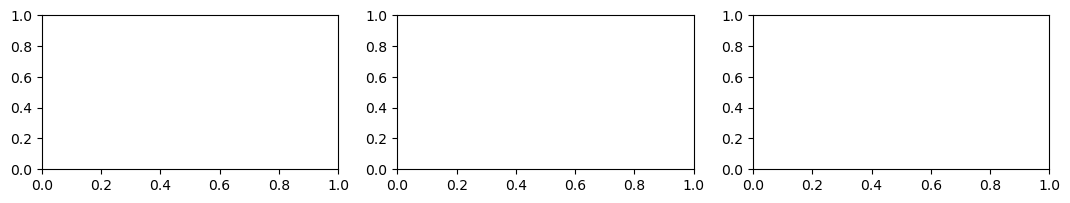

In [2]:
# usual global params
Npts = 1000                     # number of points
deltaT = 0.01                   # [s] sampling interval (sampling Rate is inverse of deltaT = 100 Hz)
t = np.arange(Npts) * deltaT    # temporal points

# f1 = 1.0     # frequency 1 (Hz)
# f2 = 4.0     # frequ?ency 2 (Hz)

# def waveform_something(x, f=1.0):
    # return something

######## SAMPLE PIPELINE ########
# given signal (s) data and time step (dt = 1/fs)
# N = length of signal
# amplitude: np.fft(signal)  ---> shift the result with np.fft.fftshift(...)
# frequency: np.fft.fftfreq(N, d=dt) --> shift the result with np.fft.fftfreq(...)
# phase: np.angle(shifted fft amp) --> unwrap 

# plotting

fig, axes = plt.subplots(1, 3, figsize=(13, 2))

# LEFT: plot signal vs time
# CENTER: plot absolute of shifted amplitude (note it since it is complex in nature) vs shifted frequency
# RIGHT: plot unwrapped phase vs shifted frequency
# make sure to add axes labels and title

# see section 3 plotting notes for the structure
# the goal here is to familiarize with how `np.fft` works and what do they mean when applied on waves

In [3]:
# sinusoids

In [4]:
# sum of sinusoids

In [5]:
# product of sinusoids

In [6]:
# square wave

In [7]:
# triangle wave

In [8]:
# gaussian function

In [9]:
# finite time sinusoid

In [10]:
# gaussian wave packet

#### Problem 1 code summary

Include a brief summary (2–3 sentences) at the bottom of your code outlining the purpose of the script and its core algorithm. Focus on explaining why you wrote the code this way and the reasoning behind your implementation choices.

### Problem 2: Shannon-Nyquist sampling theorem and aliasing
1. Specify a fixed target frequency $f_0$, duration, and amplitude. Generate a sine wave using those parameters.
2. Create a sampled wave. Keep the original signal frequency $f_0$ constant. To sample the wave, do not change $f_0$ inside the sine function. Instead, create a discrete time vector `t_samp`$=[0, \text{duration}]$  using a step size of $\Delta t = \frac{1}{f_s}$.
3. Evaluate your wave at these discrete sample points using $x_{\text{samp}} = \text{amplitude} \cdot \sin(2\pi f_0 \, \texttt{t\_samp})$ across the three required regimes:
    - Well-Sampled Rate ($f_{s,\text{high}} > 2f_0$): Sample well above the Nyquist rate to accurately capture the waveform (e.g., $f_s = 30\text{ Hz}$ for a $6\text{ Hz}$ wave).
    - Exact Nyquist Limit ($f_{s,\text{Nyquist}} = 2f_0$): Sample at exactly twice the signal frequency (e.g., $f_s = 12\text{ Hz}$ for a $6\text{ Hz}$ wave).
    - Under-Sampled Rate ($f_{s,\text{low}} < 2f_0$): Sample below the Nyquist rate to induce aliasing (e.g., $f_s = 8\text{ Hz}$ for a $6\text{ Hz}$ wave).
4. Compute the discreet Fourier transform (FFT) of both discrete signals ($x_{\text{correct}}[n]$ and $x_{\text{aliased}}[n]$)
5. Compare the detected peak frequencies in the **magnitude spectra** of both sampled signals against the true frequency $f_0$

**[REPORT FIGURE]**
- Generate a $1\times 2$ plot.
- Left is time-Domain Comparison: plot the true continuous baseline signal $x(t)$ alongside the reconstructed waveforms resulting from both sampling rates ($f_{s,\text{high}}$ and $f_{s,\text{low}}$).
- Right is frequency-Domain Comparison: plot the magnitude spectra $|X(f)|$ for both sampled signals, marking the true peak location $f_0$ and any shifted (aliased) spectral peaks.

**[REPORT DISCUSSION]**
- Explain the report figure and the Nyquist theorem. Given the highest frequency in my signal, what is the minimum sampling rate required to avoid distortion? Compare the fourier transforms of the sampled signal (sufficently vs undersampled)? Why does measuring a wave too slowly tricks the system into seeing a lower frequency? (Answer in $3$ sentences)

In [ ]:
# code

#### Problem 2 code summary

Include a brief summary (2–3 sentences) at the bottom of your code outlining the purpose of the script and its core algorithm. Focus on explaining why you wrote the code this way and the reasoning behind your implementation choices.

---
## Section 3: Notes

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from math import pi

### Fourier transform (from $t$-space to $\omega$-space)
$$ Y(\omega) = \int_{-\infty}^{+\infty} dt \frac{e^{-i\omega t}}{\sqrt{2\pi}}y(t)$$

### Inverse Fourier transform (from $\omega$-space to $t$-space)
$$ y(t) = \int_{-\infty}^{+\infty} d\omega Y(\omega) \frac{e^{i\omega t}}{\sqrt{2\pi}}$$

Something to think about: while we essentially do numerical integration, we do not impose h. Instead, we utilize the spacing of the dataset.

### Discrete FT/IFT

$$ Y_n = \frac{1}{\sqrt{2\pi}} \sum_{k=1}^N \left[(\cos(nk\theta)\Re\{y_k\}  +\sin(nk\theta)\Im\{y_k\} +i(\cos(nk\theta)\Im\{y_k\} −\sin(nk\theta)\Re\{y_k\})]\right]$$

$$ y_k = \frac{\sqrt{2\pi}}{N} \sum_{k=1}^N \left[(\cos(nk\theta)\Re\{Y_n\}  -\sin(nk\theta)\Im\{Y_n\} +i(\cos(nk\theta)\Im\{Y_n\} +\sin(nk\theta)\Re\{Y_n\})]\right]$$

Why bother it doing this way? 

It cleanly splits the real and imaginary part for both inputs and outputs, so that you can use a pair of floats rather than an aggregate complex data type (complex128 is just a pair of float64 anyway).

Using $Z=e^{−i\theta}, \rightarrow Z^{\pm nk} = e^{\mp ink\theta} = \cos(nk\theta)\mp i\sin(nk\theta)$.

(0.0, 4.0)

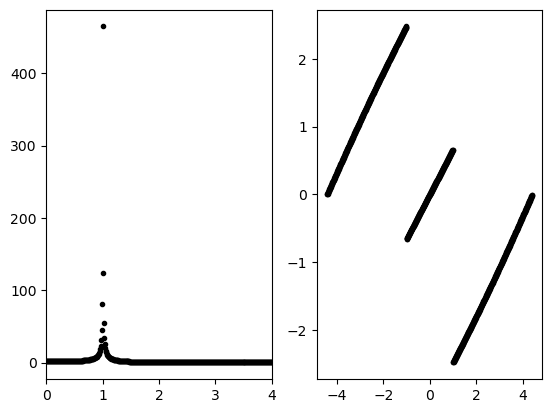

In [12]:
import numpy as np
import matplotlib.pyplot as plt

N = 1000
x = np.linspace(0, 18*2*np.pi, N)
deltaT = x[1] - x[0]

f = 1
y = np.cos(2*np.pi*f*x)

freqs = np.fft.fftfreq(N, deltaT)
Yk = np.fft.fft(y)

# # Q: Why do fftshift?
# Yk = np.fft.fftshift(Yk)

Yk_mag = np.abs(Yk)
Yk_phase = np.angle(Yk)
# Q: Why unwrap?
Yk_phase = np.unwrap(Yk_phase)

fig, ax = plt.subplots(1,2)

ax[0].plot(freqs, Yk_mag, "k.")
ax[1].plot(freqs, Yk_phase, "k.")
ax[0].set_xlim(0, 4)

Text(0, 0.5, 'x')

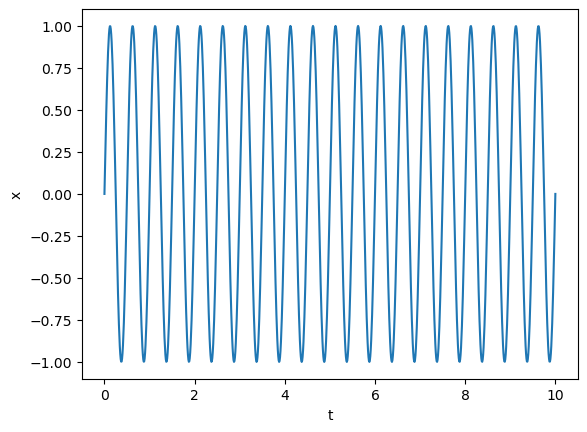

In [13]:
t = np.linspace(0,10,1000) #Create 100 pts from 0 to 10
x = np.sin(2*np.pi*2*t)
plt.plot(t,x)
plt.xlabel("t")
plt.ylabel("x")

In [14]:
x_ft = np.fft.fft(x)
np.fft.fftfreq?

Signature: np.fft.fftfreq(n, d=1.0)
Docstring:
Return the Discrete Fourier Transform sample frequencies.

The returned float array `f` contains the frequency bin centers in cycles
per unit of the sample spacing (with zero at the start).  For instance, if
the sample spacing is in seconds, then the frequency unit is cycles/second.

Given a window length `n` and a sample spacing `d`::

  f = [0, 1, ...,   n/2-1,     -n/2, ..., -1] / (d*n)   if n is even
  f = [0, 1, ..., (n-1)/2, -(n-1)/2, ..., -1] / (d*n)   if n is odd

Parameters
----------
n : int
    Window length.
d : scalar, optional
    Sample spacing (inverse of the sampling rate). Defaults to 1.

Returns
-------
f : ndarray
    Array of length `n` containing the sample frequencies.

Examples
--------
>>> signal = np.array([-2, 8, 6, 4, 1, 0, 3, 5], dtype=float)
>>> fourier = np.fft.fft(signal)
>>> n = signal.size
>>> timestep = 0.1
>>> freq = np.fft.fftfreq(n, d=timestep)
>>> freq
array([ 0.  ,  1.25,  2.5 , ..., -3.75, -2.5 , -1

In [15]:
np.fft.fftshift?

Signature: np.fft.fftshift(x, axes=None)
Docstring:
Shift the zero-frequency component to the center of the spectrum.

This function swaps half-spaces for all axes listed (defaults to all).
Note that ``y[0]`` is the Nyquist component only if ``len(x)`` is even.

Parameters
----------
x : array_like
    Input array.
axes : int or shape tuple, optional
    Axes over which to shift.  Default is None, which shifts all axes.

Returns
-------
y : ndarray
    The shifted array.

See Also
--------
ifftshift : The inverse of `fftshift`.

Examples
--------
>>> freqs = np.fft.fftfreq(10, 0.1)
>>> freqs
array([ 0.,  1.,  2., ..., -3., -2., -1.])
>>> np.fft.fftshift(freqs)
array([-5., -4., -3., -2., -1.,  0.,  1.,  2.,  3.,  4.])

Shift the zero-frequency component only along the second axis:

>>> freqs = np.fft.fftfreq(9, d=1./9).reshape(3, 3)
>>> freqs
array([[ 0.,  1.,  2.],
       [ 3.,  4., -4.],
       [-3., -2., -1.]])
>>> np.fft.fftshift(freqs, axes=(1,))
array([[ 2.,  0.,  1.],
       [-4.

### Plotting

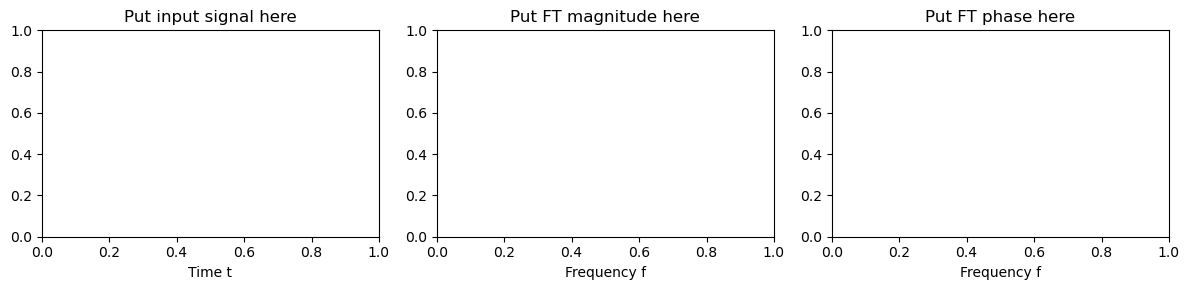

In [16]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3))

ax[0].set_title("Put input signal here")
ax[0].set_xlabel("Time t")
#....
ax[1].set_title("Put FT magnitude here")
ax[1].set_xlabel("Frequency f")
#....
ax[2].set_title("Put FT phase here")
ax[2].set_xlabel("Frequency f")
#...

fig.tight_layout()

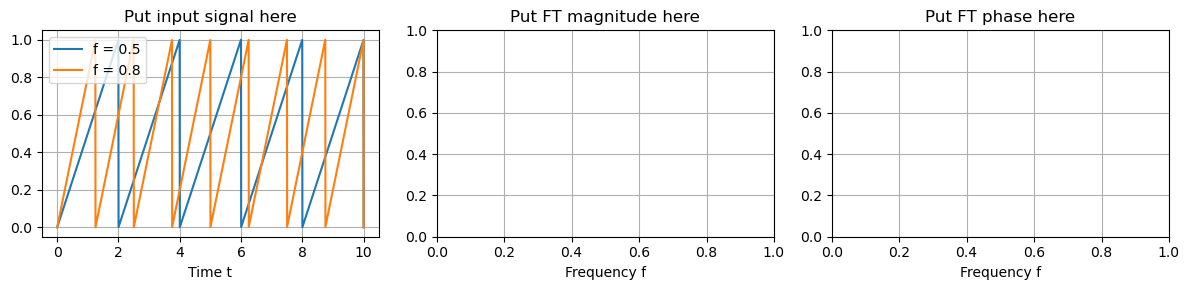

In [17]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3))
ax_t, ax_f, ax_p = axs

t = np.linspace(0, 10, 2048)
f = 0.5 # Frequency
T = 1/(f) # Period
f2 = 0.8 # Frequency
T2 = 1/(f2) # Period


ax_t.set_title("Put input signal here")
ax_t.set_xlabel("Time t")
ax_t.plot(t, (t%T)/T, label="f = 0.5")
ax_t.plot(t, (t%T2)/T2, label="f = 0.8")
ax_t.legend()
#....
ax_f.set_title("Put FT magnitude here")
ax_f.set_xlabel("Frequency f")
#....
ax_p.set_title("Put FT phase here")
ax_p.set_xlabel("Frequency f")
#...


for ax in axs:
    ax.grid(True)
fig.tight_layout()

### Others: Trigonometric interpolation (Approximation)

In [18]:
def f(x):
    return np.exp(np.sin(2*x))

def generatedata(n,f):
    dataxs = 2*pi*np.arange(n)/n
    datays = f(dataxs)
    return dataxs, datays
    
def computeparams(dataxs,datays):
    n = dataxs.size
    m = n//2
    aparams = np.zeros(m+1)
    bparams = np.zeros(m-1)
    for k in range(m+1):
        aparams[k] = datays@np.cos(k*dataxs)/m
    for k in range(1,m):
        bparams[k-1] = datays@np.sin(k*dataxs)/m
    return aparams, bparams
    
def triginterp(aparams,bparams,x):
    n = aparams.size + bparams.size
    m = n//2
    val = 0.5*(aparams[0] + aparams[-1]*np.cos(m*x))
    for k in range(1,m):
        val += aparams[k]*np.cos(k*x)
        val += bparams[k-1]*np.sin(k*x)
    return val

In [19]:
dataxs, datays = generatedata(6, f)
aparams, bparams = computeparams(dataxs, datays)
x = 0.3; pofx = triginterp(aparams, bparams, x)
print(x,pofx)

0.3 1.684381680460296
